# eWAKA × Bolt Send — Rider Performance & Three-Tier Allocation Strategy
**SCU MSBA Analytics Showdown · Fall 2026 · Sponsor: eWAKA**

This notebook tells one story in five parts:

| Part | Question | Analysis |
|---|---|---|
| 1 | **What is the problem?** | Current performance: completion, cancellation, utilisation |
| 2 | **Why is it happening?** | Demand analysis, cancellation analysis, rider segmentation |
| 3 | **What should eWAKA do?** | Three-tier rider allocation strategy |
| 4 | **What improvement can be achieved?** | Allocation simulation (25% / 50% / 100% scenarios) |
| 5 | **Business impact** | Completion ↑, cancellation ↓, utilisation ↑, Ksh value |

**Terminology (confirmed by eWAKA in the Q&A Hub):** in these files *Driver* = the courier doing the delivery, and *Rider* = the **customer**. So "Rider cancelled" means the *customer* cancelled. We say **courier** and **customer** throughout to avoid confusion.

## 0. Setup and data preparation
The raw files stay in the competition folder; we only point to them. Everything below runs top-to-bottom in about a minute (most of that is reading the 11 MB Excel file).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

DATA_DIR = "."  # folder with the two Excel files
RNG_SEED = 42

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

TIER_ORDER = ["Top 25%", "Middle 50%", "Bottom 25%"]
TIER_COLORS = {"Top 25%": "#2a9d8f", "Middle 50%": "#8d99ae", "Bottom 25%": "#e76f51"}
pct = mtick.PercentFormatter(1.0)

hist_raw = pd.read_excel(f"{DATA_DIR}/boltsend_rider_history.xlsx")
perf_raw = pd.read_excel(f"{DATA_DIR}/boltsend_rider_perfomance.xlsx")
print("history (order events):", hist_raw.shape)
print("performance (courier-days):", perf_raw.shape)

history (order events): (110578, 21)
performance (courier-days): (15351, 16)


### 0.1 Cleaning decisions
These come from profiling the data and from eWAKA's answers in the Q&A Hub:

1. **Local time.** Order timestamps are converted to Nairobi time (UTC+3) so that hour-of-day and weekday are correct.
2. **Status groups.** The six statuses are grouped into three outcomes:
   - **Completed**: Finished
   - **Customer-side cancellation**: Rider cancelled, Rider did not show
   - **Courier-side loss**: Driver cancelled, Driver rejected, Driver did not respond
3. **Optional rides are excluded** from completion and cancellation rates. These are orders outside the courier's pickup radius or flagged for safety. Bolt doesn't count them against a courier, and none of the 6,182 in the data were ever completed.
4. **Vehicle class.** *eWAKA Shujaa 2.0* = bicycle. *eWAKA Jasiri* and *RhingGo M300* = motorbike.
5. **Utilisation is capped at 100%.** 98 courier-days are above 1 because a trip ran past the logged online time. A **0★ rating means "not rated"**, so it is set to missing. Columns that are always 0 or never change (booking fee, cancellation fee, `type`) are dropped.

In [2]:
STATUS_GROUP = {
    "Finished": "Completed",
    "Rider cancelled": "Customer-side cancellation",
    "Rider did not show": "Customer-side cancellation",
    "Driver cancelled": "Courier-side loss",
    "Driver rejected": "Courier-side loss",
    "Driver did not respond": "Courier-side loss",
}
VEHICLE_CLASS = {"eWAKA Shujaa 2.0": "Bicycle", "eWAKA Jasiri": "Motorbike", "RhingGo M300": "Motorbike"}

hist = hist_raw.drop(columns=["booking_feesksh", "cancellation_feesksh", "type", "created_by"]).copy()
hist["ts"] = pd.to_datetime(hist["date"], utc=True).dt.tz_convert("Africa/Nairobi")
hist["day"] = hist["ts"].dt.tz_localize(None).dt.normalize()
hist["hour"] = hist["ts"].dt.hour
hist["weekday"] = pd.Categorical(hist["ts"].dt.day_name(),
    ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"], ordered=True)
hist["month"] = hist["ts"].dt.tz_localize(None).dt.to_period("M")
hist["outcome"] = hist["status"].map(STATUS_GROUP)
hist["vehicle_class"] = hist["vehicle_model"].map(VEHICLE_CLASS)
hist["is_optional"] = hist["optional_ride"].notna()
hist["completed"] = (hist["outcome"] == "Completed").astype(int)
hist["courier_loss"] = (hist["outcome"] == "Courier-side loss").astype(int)
hist["customer_cancel"] = (hist["outcome"] == "Customer-side cancellation").astype(int)
hist["cancelled"] = hist["courier_loss"] | hist["customer_cancel"]

orders = hist[~hist["is_optional"]].copy()   # the analysis universe

perf = perf_raw.copy()
perf["day"] = pd.to_datetime(perf["report_date"]).dt.normalize()
perf["month"] = perf["day"].dt.to_period("M")
perf["utilisation_capped"] = perf["utilisation"].clip(upper=1)
perf["active_min"] = perf["utilisation_capped"] * perf["online_time_min"]   # minutes on an active ride
perf["average_driver_rating"] = perf["average_driver_rating"].replace(0, np.nan)

assert hist["outcome"].notna().all(), "unmapped status"
assert orders[["completed", "courier_loss", "customer_cancel"]].sum(axis=1).eq(1).all()
print(f"Orders analysed (non-optional): {len(orders):,}   |   optional rides excluded: {hist['is_optional'].sum():,}")
print(f"Couriers: history {hist.individual_identifier.nunique()}, performance {perf.individual_identifier.nunique()}")

Orders analysed (non-optional): 104,396   |   optional rides excluded: 6,182
Couriers: history 287, performance 297


### 0.2 Does the utilisation metric match the trip data?
Bolt defines utilisation as the share of online time spent *on an active ride*. Before we use it in the simulation we check what "active" means. We compare utilisation × online minutes from the performance file with the trip minutes from the history file for the same courier-day.

In [3]:
fin_day = (orders[orders.completed == 1]
           .groupby(["individual_identifier", "day"])
           .agg(ride_min=("ride_duration_min", "sum"), pickup_min=("pickup_duration_min", "sum"),
                hist_finished=("completed", "sum"))
           .reset_index())
chk = perf.merge(fin_day, on=["individual_identifier", "day"], how="inner")
chk = chk[chk.online_time_min > 0]
print(f"Finished rides/day match between files: {(chk.finished_rides == chk.hist_finished).mean():.1%}")
print(f"Active minutes ÷ ride minutes          : {chk.active_min.sum() / chk.ride_min.sum():.2f}")
print(f"Active minutes ÷ (pickup + ride) minutes: {chk.active_min.sum() / (chk.ride_min + chk.pickup_min).sum():.2f}")

Finished rides/day match between files: 99.3%
Active minutes ÷ ride minutes          : 1.06
Active minutes ÷ (pickup + ride) minutes: 0.82


**Takeaway:** the two files agree, and active time is about equal to **ride** minutes (pickup to drop-off), not including the drive to pickup. So in Part 4 an extra completed order raises utilisation by its *ride* minutes only.

---
# Part 1: What is the problem? (Current performance)
Three headline KPIs:
- **Completion rate** = completed orders ÷ all (non-optional) orders
- **Cancellation rate** = customer-side cancellations + courier-side losses, ÷ all orders. We show the two sides separately because eWAKA can mainly influence the courier side.
- **Utilisation** = minutes on an active ride ÷ online minutes, summed across all couriers and days (time-weighted)

In [4]:
def kpis(o, p=None):
    out = {
        "Orders": len(o),
        "Completion rate": o.completed.mean(),
        "Cancellation rate (total)": o.cancelled.mean(),
        "  Customer-side cancellation": o.customer_cancel.mean(),
        "  Courier-side loss": o.courier_loss.mean(),
    }
    if p is not None:
        out["Utilisation"] = p.active_min.sum() / p.online_time_min.sum()
    return pd.Series(out)

baseline = kpis(orders, perf)
BASE_COMPLETION, BASE_CANCEL, BASE_UTIL = baseline["Completion rate"], baseline["Cancellation rate (total)"], baseline["Utilisation"]
display(baseline.to_frame("Jan 2025 – Aug 2026").style.format(
    lambda v: f"{v:,.0f}" if v > 1 else f"{v:.1%}"))

print("Status detail (share of non-optional orders):")
display(orders.status.value_counts(normalize=True).to_frame("share").style.format("{:.1%}"))

,Jan 2025 – Aug 2026
Orders,"104,396"
Completion rate,56.3%
Cancellation rate (total),43.7%
Customer-side cancellation,27.3%
Courier-side loss,16.4%
Utilisation,48.6%


Status detail (share of non-optional orders):


,share
status,
Finished,56.3%
Rider cancelled,26.1%
Driver did not respond,9.9%
Driver cancelled,4.8%
Driver rejected,1.7%
Rider did not show,1.3%


### 1.1 How the KPIs changed over time
The dashed line marks **Mar 2026, when Bolt Send stopped allowing bicycles** (eWAKA, Q&A Hub Q5a). After that only 6–12 couriers are active each month, so treat the later months as noisy.

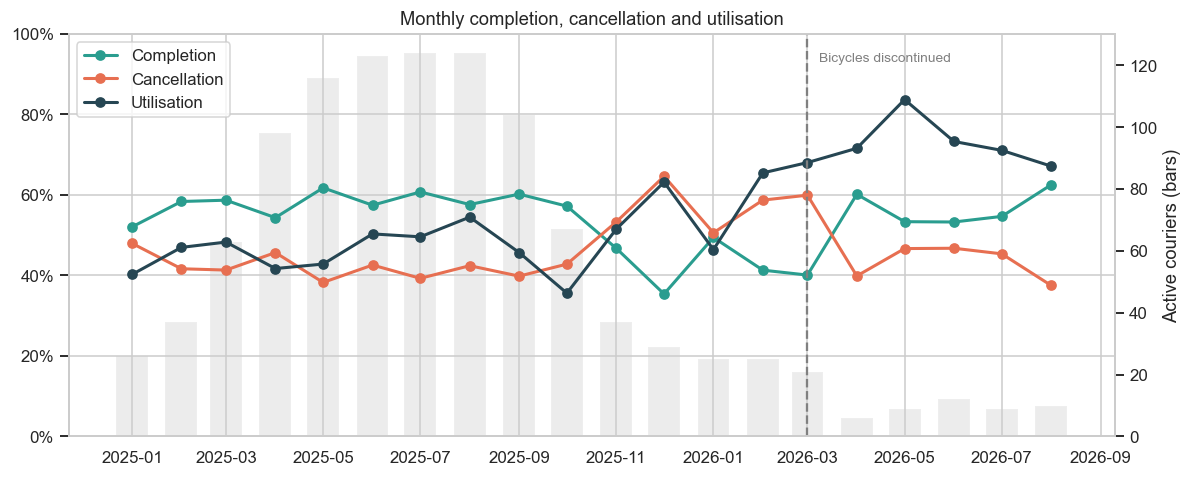

,n,couriers,completion,cancellation,utilisation
month,,,,,
2025-01,"1,668",26,52.0%,48.0%,40.2%
2025-02,"3,892",37,58.4%,41.6%,47.0%
2025-03,"6,483",63,58.7%,41.3%,48.3%
2025-04,"8,963",98,54.3%,45.7%,41.7%
2025-05,"9,839",116,61.7%,38.3%,42.8%
2025-06,"9,753",123,57.4%,42.6%,50.3%
2025-07,"11,598",124,60.7%,39.3%,49.6%
2025-08,"14,757",124,57.6%,42.4%,54.5%
2025-09,"11,410",104,60.2%,39.8%,45.7%


In [5]:
m_orders = orders.groupby("month").agg(completion=("completed", "mean"), cancellation=("cancelled", "mean"),
                                        couriers=("individual_identifier", "nunique"), n=("completed", "size"))
m_perf = perf.groupby("month").agg(active=("active_min", "sum"), online=("online_time_min", "sum"))
m_orders["utilisation"] = m_perf["active"] / m_perf["online"]
monthly = m_orders.copy(); monthly.index = monthly.index.to_timestamp()

fig, ax = plt.subplots(figsize=(11, 4.5))
for col, c in [("completion", "#2a9d8f"), ("cancellation", "#e76f51"), ("utilisation", "#264653")]:
    ax.plot(monthly.index, monthly[col], marker="o", lw=2, color=c, label=col.capitalize())
ax.axvline(pd.Timestamp("2026-03-01"), ls="--", color="grey")
ax.text(pd.Timestamp("2026-03-08"), 0.93, "Bicycles discontinued", color="grey", fontsize=9)
ax2 = ax.twinx(); ax2.bar(monthly.index, monthly.couriers, width=20, alpha=0.15, color="grey"); ax2.set_ylabel("Active couriers (bars)"); ax2.grid(False)
ax.set_zorder(ax2.get_zorder() + 1); ax.patch.set_visible(False)
ax.yaxis.set_major_formatter(pct); ax.set_ylim(0, 1); ax.legend(loc="upper left")
ax.set_title("Monthly completion, cancellation and utilisation"); plt.tight_layout(); plt.show()
display(m_orders[["n", "couriers", "completion", "cancellation", "utilisation"]].style.format(
    {"n": "{:,}", "couriers": "{:,}", "completion": "{:.1%}", "cancellation": "{:.1%}", "utilisation": "{:.1%}"}))

### 1.2 Bicycles vs. motorbikes

In [6]:
veh = orders.groupby("vehicle_class").agg(
    orders=("completed", "size"), couriers=("individual_identifier", "nunique"),
    completion=("completed", "mean"), customer_cancel=("customer_cancel", "mean"), courier_loss=("courier_loss", "mean"),
    no_response=("status", lambda s: (s == "Driver did not respond").mean()))
fin = orders[orders.completed == 1]
veh["median_pickup_min"] = fin.groupby("vehicle_class").pickup_duration_min.median()
veh["median_ride_min"] = fin.groupby("vehicle_class").ride_duration_min.median()
display(veh.style.format({"orders": "{:,}", "completion": "{:.1%}", "customer_cancel": "{:.1%}",
                          "courier_loss": "{:.1%}", "no_response": "{:.1%}", "median_pickup_min": "{:.1f}", "median_ride_min": "{:.1f}"}))

,orders,couriers,completion,customer_cancel,courier_loss,no_response,median_pickup_min,median_ride_min
vehicle_class,,,,,,,,
Bicycle,"94,669",262,56.3%,27.5%,16.1%,9.5%,10.1,36.8
Motorbike,"9,727",25,56.2%,25.2%,18.6%,14.0%,4.3,22.2


**Part 1 summary: the problem.** Only about half of all orders are completed. About a quarter are cancelled by the customer, and roughly one in five is lost on the courier side, mostly because the courier **didn't respond** to the offer. Couriers spend less than half their online time on a ride. Motorbikes pick up and deliver much faster, but they have a *higher* non-response rate.

---
# Part 2: Why is it happening?
## 2.1 Demand analysis: peak hours and busy days
Demand is measured as order requests, based on the time each order was created (Nairobi time). **Peak hours** are the top quartile (6 of 24) of hours by request volume.

Peak hours: 12:00, 13:00, 14:00, 15:00, 16:00, 17:00
Share of all requests in peak hours: 58.8% (in 25% of the hours)


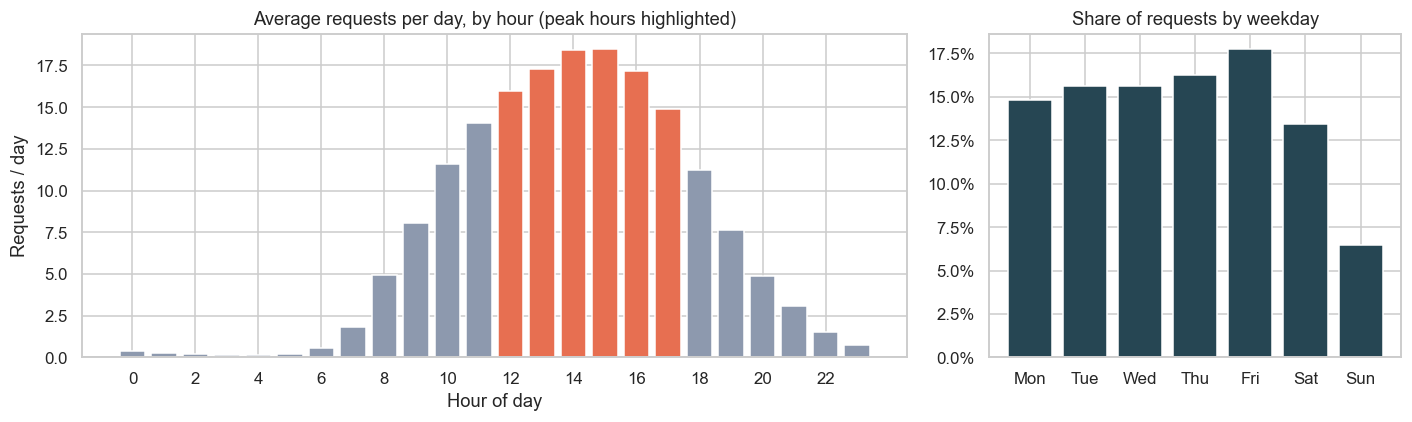

,requests,completion,share
weekday,,,
Friday,"18,526",53.8%,17.7%
Thursday,"16,957",56.5%,16.2%
Tuesday,"16,332",57.5%,15.6%
Wednesday,"16,327",57.9%,15.6%
Monday,"15,445",57.8%,14.8%
Saturday,"14,035",55.7%,13.4%
Sunday,"6,774",54.1%,6.5%


In [7]:
n_days = orders["day"].nunique()
by_hour = orders.groupby("hour").agg(requests=("completed", "size"), completion=("completed", "mean"),
                                      courier_loss=("courier_loss", "mean"), customer_cancel=("customer_cancel", "mean"))
by_hour = by_hour.reindex(range(24), fill_value=0)
by_hour["requests_per_day"] = by_hour["requests"] / n_days
PEAK_HOURS = sorted(by_hour["requests"].nlargest(6).index.tolist())
orders["is_peak"] = orders["hour"].isin(PEAK_HOURS)
print("Peak hours:", ", ".join(f"{h:02d}:00" for h in PEAK_HOURS))
print(f"Share of all requests in peak hours: {orders.is_peak.mean():.1%} (in 25% of the hours)")

by_day = orders.groupby("weekday", observed=True).agg(requests=("completed", "size"), completion=("completed", "mean"))
by_day["share"] = by_day.requests / by_day.requests.sum()

fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [2, 1]})
cols = ["#e76f51" if h in PEAK_HOURS else "#8d99ae" for h in by_hour.index]
axes[0].bar(by_hour.index, by_hour.requests_per_day, color=cols)
axes[0].set(title="Average requests per day, by hour (peak hours highlighted)", xlabel="Hour of day", ylabel="Requests / day")
axes[0].set_xticks(range(0, 24, 2))
axes[1].bar(by_day.index.astype(str).str[:3], by_day.share, color="#264653")
axes[1].yaxis.set_major_formatter(pct); axes[1].set(title="Share of requests by weekday", ylabel="")
plt.tight_layout(); plt.show()
display(by_day.sort_values("requests", ascending=False).style.format({"requests": "{:,}", "completion": "{:.1%}", "share": "{:.1%}"}))

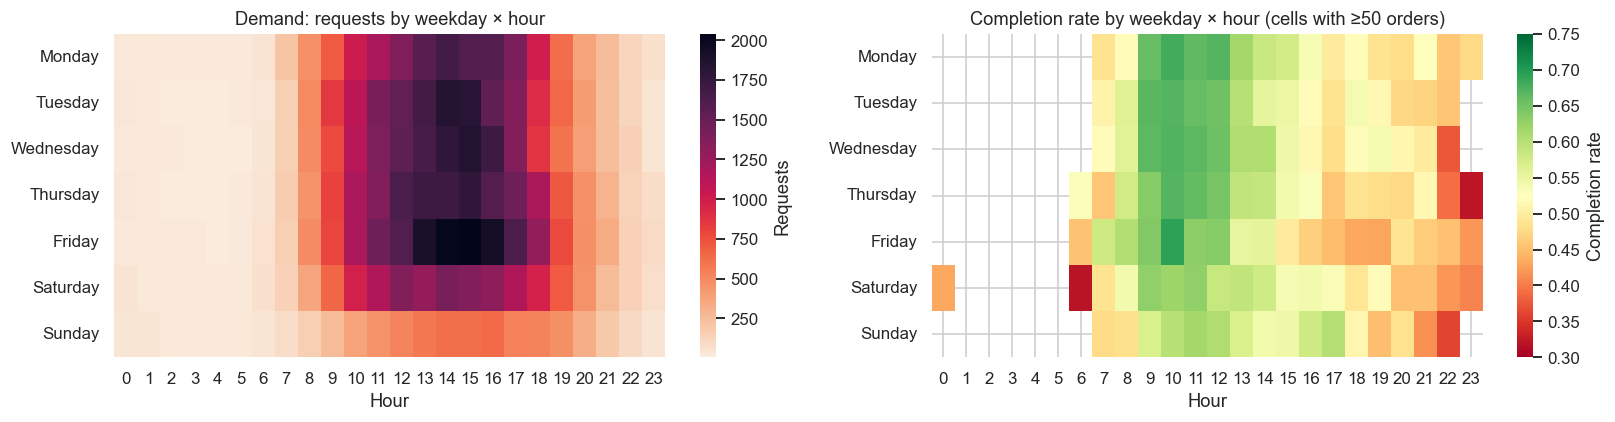

In [8]:
heat = orders.pivot_table(index="weekday", columns="hour", values="completed", aggfunc="size", observed=True).fillna(0)
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
sns.heatmap(heat, cmap="rocket_r", ax=ax[0], cbar_kws={"label": "Requests"})
ax[0].set(title="Demand: requests by weekday × hour", xlabel="Hour", ylabel="")
comp = orders.pivot_table(index="weekday", columns="hour", values="completed", aggfunc="mean", observed=True)
sns.heatmap(comp.where(heat >= 50), cmap="RdYlGn", vmin=0.3, vmax=0.75, ax=ax[1], cbar_kws={"label": "Completion rate"})
ax[1].set(title="Completion rate by weekday × hour (cells with ≥50 orders)", xlabel="Hour", ylabel="")
plt.tight_layout(); plt.show()

### 2.1b Is there enough courier supply when demand peaks?
For each date and hour we count requests and **distinct couriers who had at least one order event**. Then we average by hour of day. Requests per active courier is a simple measure of pressure on supply.

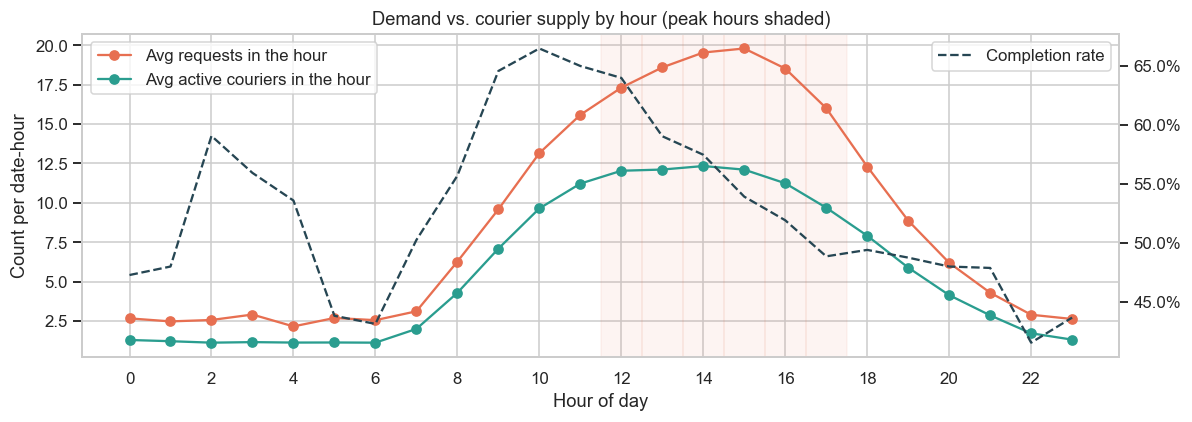

,completed,customer_cancel,courier_loss
is_peak,,,
Off-peak,56.9%,27.3%,15.8%
Peak,55.9%,27.4%,16.7%


In [9]:
slot = orders.groupby(["day", "hour"]).agg(requests=("completed", "size"), couriers=("individual_identifier", "nunique"),
                                            completion=("completed", "mean"))
sup = slot.groupby("hour")[["requests", "couriers"]].mean().reindex(range(24))
sup["requests_per_courier"] = sup.requests / sup.couriers
sup["completion"] = by_hour["completion"]

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(sup.index, sup.requests, marker="o", color="#e76f51", label="Avg requests in the hour")
ax.plot(sup.index, sup.couriers, marker="o", color="#2a9d8f", label="Avg active couriers in the hour")
for h in PEAK_HOURS: ax.axvspan(h - 0.5, h + 0.5, color="#e76f51", alpha=0.07)
ax.set(xlabel="Hour of day", ylabel="Count per date-hour", title="Demand vs. courier supply by hour (peak hours shaded)")
ax.set_xticks(range(0, 24, 2)); ax.legend(loc="upper left")
ax2 = ax.twinx(); ax2.plot(sup.index, sup.completion, ls="--", color="#264653", label="Completion rate"); ax2.yaxis.set_major_formatter(pct)
ax2.grid(False); ax2.legend(loc="upper right")
plt.tight_layout(); plt.show()
peak_cmp = orders.groupby("is_peak")[["completed", "customer_cancel", "courier_loss"]].mean().rename(index={True: "Peak", False: "Off-peak"})
display(peak_cmp.style.format("{:.1%}"))

## 2.2 Cancellation analysis
Who cancels, when, and why?

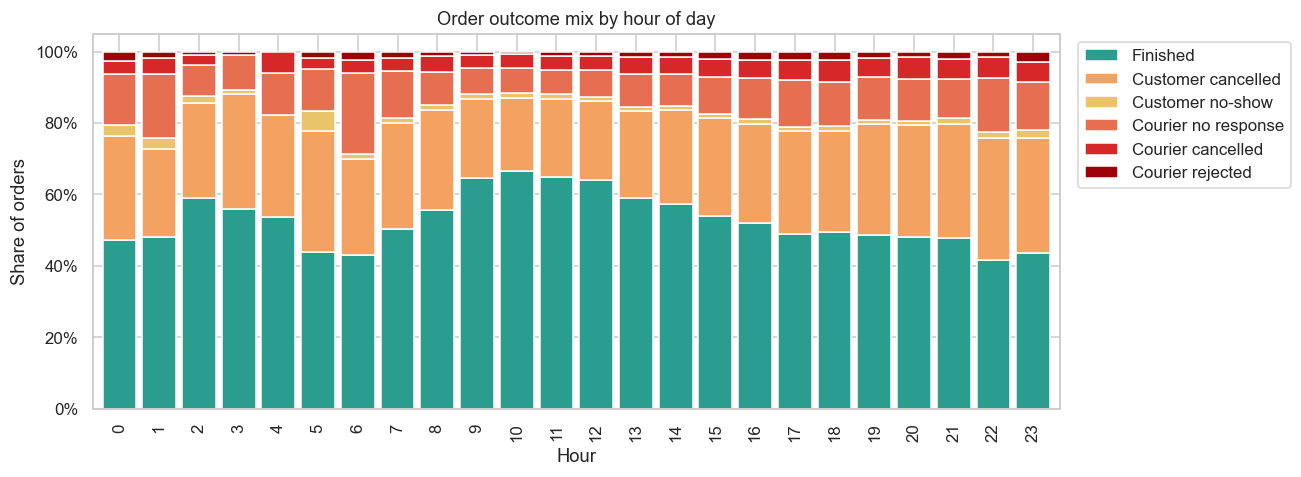

In [10]:
mix = orders.pivot_table(index="hour", columns="status", values="completed", aggfunc="size").fillna(0)
mix = mix.div(mix.sum(axis=1), axis=0)[["Finished", "Rider cancelled", "Rider did not show", "Driver did not respond", "Driver cancelled", "Driver rejected"]]
mix = mix.rename(columns={"Rider cancelled": "Customer cancelled", "Rider did not show": "Customer no-show",
                          "Driver did not respond": "Courier no response", "Driver cancelled": "Courier cancelled",
                          "Driver rejected": "Courier rejected"})
colors = ["#2a9d8f", "#f4a261", "#e9c46a", "#e76f51", "#d62828", "#9d0208"]
ax = mix.plot(kind="bar", stacked=True, figsize=(12, 4.5), color=colors, width=0.85)
ax.yaxis.set_major_formatter(pct); ax.set(title="Order outcome mix by hour of day", xlabel="Hour", ylabel="Share of orders")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left"); plt.tight_layout(); plt.show()

**Do customers cancel more on slower couriers?** Pickup duration is only recorded for *completed* orders, so we can't compare a cancelled order's own pickup time. Instead we measure each courier's **typical (median) pickup time** on completed orders, group couriers into speed quartiles, and compare how often their customers cancel.

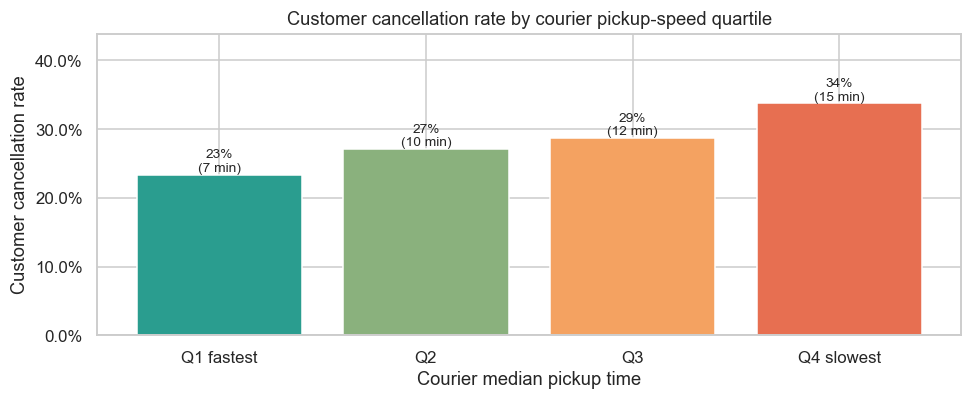

Spearman correlation, courier median pickup vs. customer cancellation rate: 0.41
Courier-side losses broken down:


,share of courier-side losses
status,
Driver did not respond,60.5%
Driver cancelled,29.3%
Driver rejected,10.2%


In [11]:
cp = orders.groupby("individual_identifier").agg(orders=("completed", "size"), cust_cancels=("customer_cancel", "sum"))
cp["median_pickup"] = orders[orders.completed == 1].groupby("individual_identifier").pickup_duration_min.median()
cp = cp[(cp.orders >= 10) & cp.median_pickup.notna()]
cp["speed_quartile"] = pd.qcut(cp.median_pickup, 4, labels=["Q1 fastest", "Q2", "Q3", "Q4 slowest"])
pb = cp.groupby("speed_quartile", observed=True).agg(couriers=("orders", "size"), orders=("orders", "sum"),
                                                     cust_cancels=("cust_cancels", "sum"), median_pickup_min=("median_pickup", "median"))
pb["customer_cancel_rate"] = pb.cust_cancels / pb.orders
fig, ax = plt.subplots(figsize=(9, 3.8))
bars = ax.bar(pb.index.astype(str), pb.customer_cancel_rate, color=["#2a9d8f", "#8ab17d", "#f4a261", "#e76f51"])
ax.bar_label(bars, labels=[f"{v:.0%}\n({m:.0f} min)" for v, m in zip(pb.customer_cancel_rate, pb.median_pickup_min)], fontsize=9)
ax.yaxis.set_major_formatter(pct); ax.set_ylim(0, pb.customer_cancel_rate.max() * 1.3)
ax.set(title="Customer cancellation rate by courier pickup-speed quartile", xlabel="Courier median pickup time", ylabel="Customer cancellation rate")
plt.tight_layout(); plt.show()
print(f"Spearman correlation, courier median pickup vs. customer cancellation rate: "
      f"{cp.median_pickup.corr(cp.cust_cancels / cp.orders, method='spearman'):.2f}")

loss = orders[orders.courier_loss == 1].status.value_counts(normalize=True)
print("Courier-side losses broken down:"); display(loss.to_frame("share of courier-side losses").style.format("{:.1%}"))

## 2.3 Rider (courier) segmentation: Top 25% / Middle 50% / Bottom 25%
Every courier gets a **composite performance score**: the average of their percentile ranks on three measures.

| Measure | Why it matters | Source |
|---|---|---|
| **Acceptance rate**: share of offers not rejected or ignored | Bolt's dispatch algorithm favours high acceptance (Q&A Hub Q4b) | history file |
| **Finish rate on accepted orders**: completed ÷ accepted | Reliability once the courier commits | history file |
| **Finished rides per online hour** | Productivity, i.e. turning online time into deliveries | performance file |

Driver score isn't used because it's 1.0 for most couriers, so it can't tell them apart. To avoid ranking couriers on almost no data, only those with **at least 5 active days and at least 10 orders** are scored. The rest are labelled *Insufficient history*.

In [12]:
MIN_DAYS, MIN_ORDERS = 5, 10
c_hist = orders.groupby("individual_identifier").agg(
    orders=("completed", "size"), completed=("completed", "sum"),
    rejected_or_ignored=("status", lambda s: s.isin(["Driver rejected", "Driver did not respond"]).sum()),
    courier_loss=("courier_loss", "mean"), customer_cancel=("customer_cancel", "mean"),
    peak_orders=("is_peak", "sum"),
    motorbike=("vehicle_class", lambda s: (s == "Motorbike").mean()),
    first_seen=("day", "min"), last_seen=("day", "max"))
c_hist["accepted"] = c_hist.orders - c_hist.rejected_or_ignored
c_hist["acceptance_rate"] = c_hist.accepted / c_hist.orders
c_hist["finish_rate_accepted"] = (c_hist.completed / c_hist.accepted).fillna(0)
c_hist["completion_rate"] = c_hist.completed / c_hist.orders
c_hist["median_pickup_min"] = orders[orders.completed == 1].groupby("individual_identifier").pickup_duration_min.median()

c_perf = perf.groupby("individual_identifier").agg(active_days=("day", "nunique"), online_min=("online_time_min", "sum"),
                                                   active_min=("active_min", "sum"), finished_rides=("finished_rides", "sum"),
                                                   rating=("average_driver_rating", "mean"))
c_perf["rides_per_online_hr"] = c_perf.finished_rides / (c_perf.online_min / 60)
c_perf["utilisation"] = c_perf.active_min / c_perf.online_min

couriers = c_hist.join(c_perf, how="inner")
eligible = (couriers.active_days >= MIN_DAYS) & (couriers.orders >= MIN_ORDERS) & (couriers.online_min > 0)
scored = couriers[eligible].copy()
for m in ["acceptance_rate", "finish_rate_accepted", "rides_per_online_hr"]:
    scored[f"pr_{m}"] = scored[m].rank(pct=True)
scored["composite_score"] = scored[[c for c in scored if c.startswith("pr_")]].mean(axis=1)
r = scored.composite_score.rank(pct=True, method="first")
scored["tier"] = np.select([r > 0.75, r <= 0.25], ["Top 25%", "Bottom 25%"], "Middle 50%")

couriers["tier"] = scored["tier"].reindex(couriers.index).fillna("Insufficient history")
assert scored.tier.value_counts().sum() == len(scored)
print(f"Scored couriers: {len(scored)}   |   insufficient history: {(~eligible).sum()}")
print(scored.tier.value_counts().reindex(TIER_ORDER).to_string())

Scored couriers: 255   |   insufficient history: 30
tier
Top 25%        64
Middle 50%    128
Bottom 25%     63


In [13]:
orders["tier"] = orders.individual_identifier.map(couriers["tier"]).fillna("Insufficient history")
perf["tier"] = perf.individual_identifier.map(couriers["tier"]).fillna("Insufficient history")

prof = scored.groupby("tier").agg(
    couriers=("orders", "size"), composite_score=("composite_score", "mean"),
    acceptance_rate=("acceptance_rate", "median"), finish_rate_accepted=("finish_rate_accepted", "median"),
    rides_per_online_hr=("rides_per_online_hr", "median"), utilisation=("utilisation", "median"),
    active_days=("active_days", "median"), median_pickup_min=("median_pickup_min", "median"),
    motorbike_share=("motorbike", "mean"), rating=("rating", "mean")).reindex(TIER_ORDER)
tot = orders.groupby("tier").agg(orders=("completed", "size"), peak_orders=("is_peak", "sum"),
                                 completion_rate=("completed", "mean"), courier_loss=("courier_loss", "mean"),
                                 customer_cancel=("customer_cancel", "mean"))
prof = prof.join(tot)
prof["share_of_orders"] = prof.orders / len(orders)
prof["share_of_peak_orders"] = prof.peak_orders / orders.is_peak.sum()
prof_t = prof.drop(columns=["orders", "peak_orders"]).T
fmt_row = {"couriers": "{:.0f}", "composite_score": "{:.2f}", "rides_per_online_hr": "{:.2f}", "active_days": "{:.0f}",
           "median_pickup_min": "{:.1f}", "rating": "{:.2f}"}
prof_disp = prof_t.apply(lambda row: row.map(lambda v: fmt_row.get(row.name, "{:.1%}").format(v)), axis=1)
display(prof_disp)
print("Rates, rides/hour, utilisation, active days and pickup are tier medians; composite score, motorbike share and rating are means;\n"
      "completion / loss / cancel rates and order shares are pooled over all the tier's orders.")

tier,Top 25%,Middle 50%,Bottom 25%
couriers,64,128,63
composite_score,0.75,0.51,0.24
acceptance_rate,97.5%,93.8%,84.5%
finish_rate_accepted,71.7%,63.6%,51.7%
rides_per_online_hr,0.89,0.64,0.46
utilisation,56.7%,46.0%,40.0%
active_days,50,32,32
median_pickup_min,10.0,10.3,12.7
motorbike_share,10.9%,6.4%,6.3%
rating,4.88,4.85,4.81


Rates, rides/hour, utilisation, active days and pickup are tier medians; composite score, motorbike share and rating are means;
completion / loss / cancel rates and order shares are pooled over all the tier's orders.


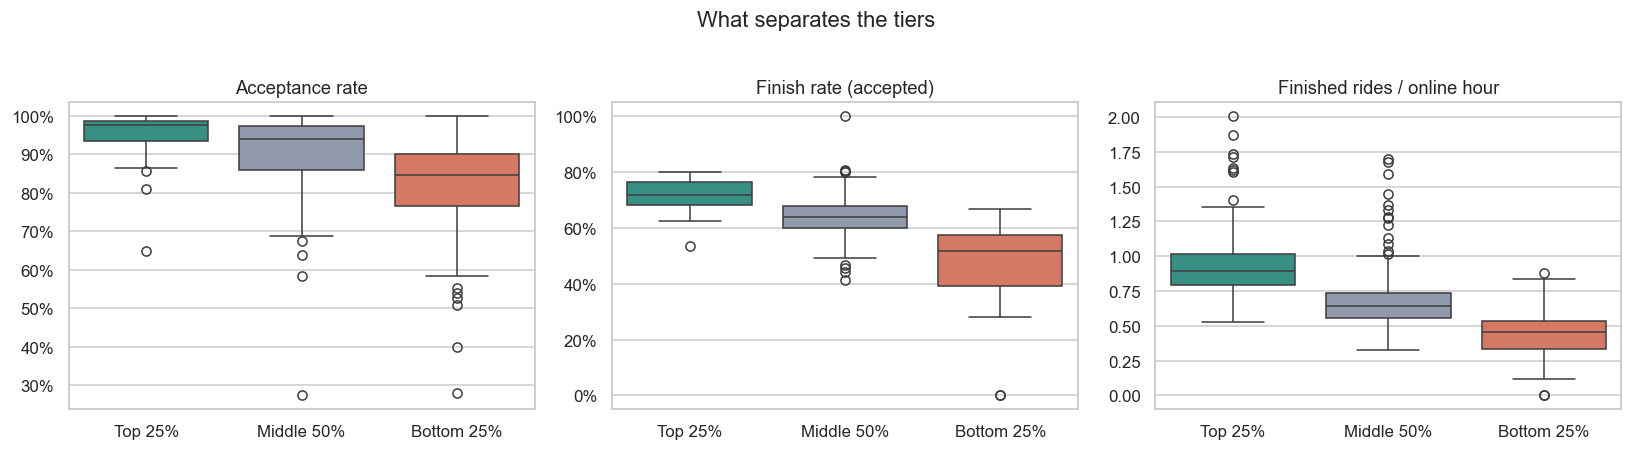

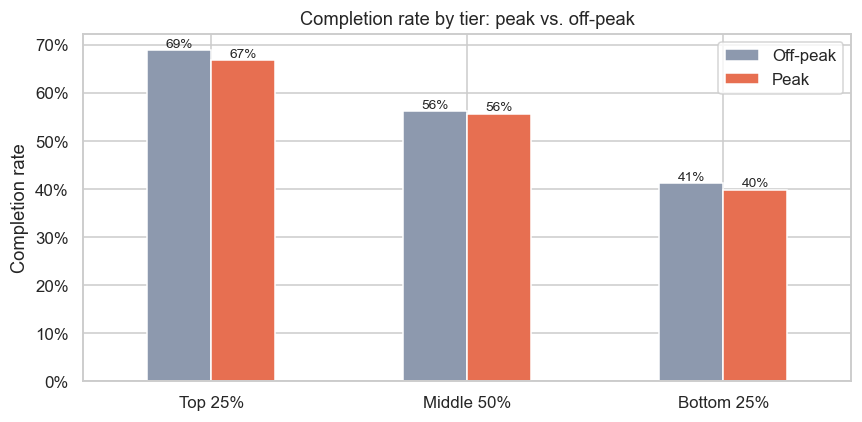

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, m, t in zip(axes, ["acceptance_rate", "finish_rate_accepted", "rides_per_online_hr"],
                    ["Acceptance rate", "Finish rate (accepted)", "Finished rides / online hour"]):
    sns.boxplot(data=scored, x="tier", y=m, order=TIER_ORDER, hue="tier", palette=TIER_COLORS, ax=ax, legend=False)
    ax.set(title=t, xlabel="", ylabel="")
    if m != "rides_per_online_hr": ax.yaxis.set_major_formatter(pct)
plt.suptitle("What separates the tiers", y=1.02); plt.tight_layout(); plt.show()

tp = orders[orders.tier.isin(TIER_ORDER)].groupby(["tier", "is_peak"]).completed.mean().unstack()
tp.columns = ["Off-peak", "Peak"]; tp = tp.reindex(TIER_ORDER)
ax = tp.plot(kind="bar", figsize=(8, 4), color=["#8d99ae", "#e76f51"], rot=0)
ax.yaxis.set_major_formatter(pct); ax.set(title="Completion rate by tier: peak vs. off-peak", xlabel="", ylabel="Completion rate")
for c in ax.containers: ax.bar_label(c, fmt=lambda v: f"{v:.0%}", fontsize=9)
plt.tight_layout(); plt.show()

**Part 2 summary: why it's happening.**
- **Demand is concentrated.** The six peak hours, 12:00–17:00, carry about 59% of all requests. Friday is the busiest day and Sunday the quietest.
- **Supply can't keep up with the afternoon peak.** Completion is highest mid-morning (about 66% at 10:00) and slides to about 49% by 17:00, as requests rise faster than the number of active couriers. (The simple peak vs. off-peak average hides this, because the weak overnight hours count as off-peak.)
- **Each tier performs about the same at peak and off-peak.** The gap is *between* couriers rather than between times of day, so who is online at peak matters most.
- **Courier non-response is the largest controllable loss**, about 60% of all courier-side losses. Bolt's algorithm then offers fewer orders to those couriers.
- **Slower couriers drive customer cancellations.** Customers of the slowest-pickup quartile of couriers cancel noticeably more often than customers of the fastest quartile.
- **Couriers perform very differently.** The Bottom tier completes far fewer of its orders, yet still handles about a fifth of peak-hour orders. So the busiest hours are partly served by the couriers least likely to complete.

---
# Part 3: What should eWAKA do? A three-tier rider allocation strategy
eWAKA runs the fleet and can't change Bolt's dispatch algorithm directly. What it *can* control is **which couriers it puts online, when, and on which vehicles**, plus coaching and incentives. It can also raise its findings with Bolt (Q&A Hub Q2e says the two companies coordinate). The strategy below is built from the evidence above:

In [15]:
peak_txt = ", ".join(f"{h:02d}:00" for h in PEAK_HOURS)
busy_days = ", ".join(by_day.sort_values("requests", ascending=False).index[:3].astype(str))
strategy = pd.DataFrame({
    "Who": TIER_ORDER,
    "Allocation rule": [
        f"Priority online during peak hours ({peak_txt}) and busiest days ({busy_days}); first claim on motorbikes",
        "Standard shifts covering peaks and off-peak; promotion to Top tier when score improves",
        "Moved to off-peak shifts; not scheduled during peak hours until score improves",
    ],
    "Support / incentive": [
        "Peak-hour bonus; retention focus (these couriers carry the platform)",
        "Coaching on response time and acceptance; alerts when an order goes unanswered",
        "Retraining on app use, response and pickup; 30-day performance review",
    ],
    "Evidence": [
        f"Completion {prof.loc['Top 25%','completion_rate']:.0%} vs. {prof.loc['Bottom 25%','completion_rate']:.0%} for Bottom tier",
        f"Courier-side loss {prof.loc['Middle 50%','courier_loss']:.0%}; non-response is {loss.get('Driver did not respond', 0):.0%} of courier-side losses",
        f"Bottom tier still handles {prof.loc['Bottom 25%','share_of_peak_orders']:.0%} of peak-hour orders",
    ],
}).set_index("Who")
display(strategy.style.set_properties(**{"text-align": "left", "white-space": "normal"}))

,Allocation rule,Support / incentive,Evidence
Who,,,
Top 25%,"Priority online during peak hours (12:00, 13:00, 14:00, 15:00, 16:00, 17:00) and busiest days (Friday, Thursday, Tuesday); first claim on motorbikes",Peak-hour bonus; retention focus (these couriers carry the platform),Completion 68% vs. 40% for Bottom tier
Middle 50%,Standard shifts covering peaks and off-peak; promotion to Top tier when score improves,Coaching on response time and acceptance; alerts when an order goes unanswered,Courier-side loss 17%; non-response is 61% of courier-side losses
Bottom 25%,Moved to off-peak shifts; not scheduled during peak hours until score improves,"Retraining on app use, response and pickup; 30-day performance review",Bottom tier still handles 19% of peak-hour orders


Tiers should be **recalculated every week** from the same composite score, so couriers can move up or down. Being placed in a tier is not a permanent label.

---
# Part 4: What improvement can be achieved? Allocation simulation
**Question:** if peak-hour orders that Bottom-tier couriers failed to complete had gone to Top or Middle couriers instead, how many more would have been completed?

**Method (expected-value simulation on the actual order log):**
1. **Eligible orders:** non-optional, peak-hour orders handled by a **Bottom 25%** courier that were *not* completed.
2. **Outcome if reassigned:** completion probability = the Top + Middle tiers' actual completion rate for the **same hour and vehicle class** (fallback: same hour only). The remaining probability is split between customer-side and courier-side using the higher tiers' own mix for that hour and vehicle.
3. **Capacity cap.** Higher tiers can only take orders when they have spare time. For each date × hour slot:
   - Spare minutes = the higher-tier couriers' idle minutes that day, i.e. (1 − utilisation) × online time, spread across the hours they were active in proportion to their orders.
   - Extra orders they can take = spare minutes ÷ the higher tiers' median minutes per completed order (pickup + ride).
4. **Scenarios:** 25%, 50% and 100% of eligible orders are put forward for reassignment (chosen at random, seed 42). Within each slot, the number actually reassigned is capped by the capacity above.
5. **Utilisation impact:** each extra expected completion adds the higher tiers' median **ride** minutes (see 0.2). Total online time stays the same.

In [16]:
HIGH = ["Top 25%", "Middle 50%"]
hi = orders[orders.tier.isin(HIGH)]

# completion / outcome probabilities for higher tiers by hour x vehicle (fallback: hour)
p_hv = hi.groupby(["hour", "vehicle_class"])[["completed", "customer_cancel", "courier_loss"]].mean()
n_hv = hi.groupby(["hour", "vehicle_class"]).size()
p_hv = p_hv[n_hv >= 30]
p_h = hi.groupby("hour")[["completed", "customer_cancel", "courier_loss"]].mean()

elig = orders[(orders.tier == "Bottom 25%") & orders.is_peak & (orders.completed == 0)].copy()
key = pd.MultiIndex.from_frame(elig[["hour", "vehicle_class"]])
probs = p_hv.reindex(key).set_axis(elig.index)
fallback = p_h.reindex(elig.hour).set_axis(elig.index)
probs = probs.fillna(fallback)
elig[["p_complete", "p_customer", "p_courier"]] = probs.values

# capacity of higher tiers per day x hour
fin_hi = hi[hi.completed == 1]
MIN_PER_ORDER = (fin_hi.pickup_duration_min + fin_hi.ride_duration_min).median()
RIDE_MIN = fin_hi.ride_duration_min.median()
idle = perf[perf.tier.isin(HIGH)].assign(idle_min=lambda d: (1 - d.utilisation_capped) * d.online_time_min)
idle = idle[["individual_identifier", "day", "idle_min"]]
hrs = hi.groupby(["individual_identifier", "day", "hour"]).size().rename("ev").reset_index()
hrs["w"] = hrs.ev / hrs.groupby(["individual_identifier", "day"]).ev.transform("sum")
hrs = hrs.merge(idle, on=["individual_identifier", "day"], how="inner")
hrs["spare_min"] = hrs.w * hrs.idle_min
cap = (hrs.groupby(["day", "hour"]).spare_min.sum() / MIN_PER_ORDER).apply(np.floor).rename("capacity_orders")

print(f"Eligible orders: {len(elig):,}  ({len(elig)/len(orders):.1%} of all orders)")
print(f"Higher-tier median minutes per completed order (pickup+ride): {MIN_PER_ORDER:.1f}; median ride minutes: {RIDE_MIN:.1f}")
print(f"Eligible orders falling in a slot with any higher-tier spare capacity: "
      f"{elig.set_index(['day','hour']).index.isin(cap[cap > 0].index).mean():.1%}")

Eligible orders: 6,981  (6.7% of all orders)
Higher-tier median minutes per completed order (pickup+ride): 44.6; median ride minutes: 34.9
Eligible orders falling in a slot with any higher-tier spare capacity: 78.8%


In [17]:
def simulate(share, seed=RNG_SEED):
    rng = np.random.default_rng(seed)
    pick = elig.sample(frac=share, random_state=rng.integers(1e9)) if share < 1 else elig
    pick = pick.sample(frac=1, random_state=seed)                  # random order inside each slot
    pick = pick.assign(rank_in_slot=pick.groupby(["day", "hour"]).cumcount())
    pick = pick.join(cap, on=["day", "hour"]).fillna({"capacity_orders": 0})
    moved = pick[pick.rank_in_slot < pick.capacity_orders]
    assert (moved.groupby(["day", "hour"]).size() <= moved.groupby(["day", "hour"]).capacity_orders.first()).all()

    n = len(orders)
    new_completed = orders.completed.sum() + moved.p_complete.sum()
    new_cust = orders.customer_cancel.sum() - moved.customer_cancel.sum() + moved.p_customer.sum()
    new_cour = orders.courier_loss.sum() - moved.courier_loss.sum() + moved.p_courier.sum()
    extra_active = moved.p_complete.sum() * RIDE_MIN
    return {
        "Scenario": f"{int(share*100)}% reallocation",
        "Orders put forward": len(pick), "Orders reallocated (capacity-capped)": len(moved),
        "Extra completed orders": moved.p_complete.sum(),
        "Completion rate": new_completed / n,
        "Cancellation rate": (new_cust + new_cour) / n,
        "Courier-side loss": new_cour / n,
        "Customer-side cancellation": new_cust / n,
        "Utilisation": (perf.active_min.sum() + extra_active) / perf.online_time_min.sum(),
    }

base_row = {"Scenario": "Baseline (actual)", "Orders put forward": 0, "Orders reallocated (capacity-capped)": 0,
            "Extra completed orders": 0.0, "Completion rate": BASE_COMPLETION, "Cancellation rate": BASE_CANCEL,
            "Courier-side loss": orders.courier_loss.mean(), "Customer-side cancellation": orders.customer_cancel.mean(),
            "Utilisation": BASE_UTIL}
sim = pd.DataFrame([base_row] + [simulate(s) for s in (0.25, 0.50, 1.00)]).set_index("Scenario")

assert (sim["Completion rate"] <= 1).all()
assert sim["Extra completed orders"].is_monotonic_increasing
assert sim["Completion rate"].is_monotonic_increasing and sim["Cancellation rate"].is_monotonic_decreasing
display(sim.style.format({"Orders put forward": "{:,.0f}", "Orders reallocated (capacity-capped)": "{:,.0f}",
                          "Extra completed orders": "{:,.0f}", "Completion rate": "{:.2%}", "Cancellation rate": "{:.2%}",
                          "Courier-side loss": "{:.2%}", "Customer-side cancellation": "{:.2%}", "Utilisation": "{:.2%}"}))

,Orders put forward,Orders reallocated (capacity-capped),Extra completed orders,Completion rate,Cancellation rate,Courier-side loss,Customer-side cancellation,Utilisation
Scenario,,,,,,,,
Baseline (actual),0,0,0,56.31%,43.69%,16.36%,27.32%,48.56%
25% reallocation,"1,745","1,288",768,57.05%,42.95%,15.96%,26.99%,49.16%
50% reallocation,"3,490","2,428","1,446",57.70%,42.30%,15.61%,26.69%,49.68%
100% reallocation,"6,981","4,612","2,749",58.95%,41.05%,14.96%,26.10%,50.69%


**Robustness check.** Which orders get "put forward" is random, so we rerun the 50% scenario with 20 different seeds to show how much the result moves.

In [18]:
spread = pd.Series([simulate(0.5, seed=s)["Extra completed orders"] for s in range(20)])
print(f"50% scenario, extra completions across 20 seeds: mean {spread.mean():,.0f}, min {spread.min():,.0f}, max {spread.max():,.0f}")

50% scenario, extra completions across 20 seeds: mean 1,465, min 1,443, max 1,486


---
# Part 5: Business impact
The impact is shown as percentage-point (pp) changes against the actual baseline. Every order ends as either completed or cancelled, so the completion increase and the cancellation decrease are always the same size. The table also shows how the cancellation decrease splits between the courier side and the customer side. Money is valued at the **median price of a completed trip** in the data. That's gross trip value: eWAKA's own share depends on its commission and lease terms, which haven't been shared yet.

In [19]:
PRICE = orders.loc[orders.completed == 1, "trip_priceksh"].median()
months = orders.month.nunique()
impact = pd.DataFrame({
    "Completion increase (pp)": (sim["Completion rate"] - BASE_COMPLETION) * 100,
    "Cancellation decrease (pp)": (BASE_CANCEL - sim["Cancellation rate"]) * 100,
    "  of which courier-side (pp)": (orders.courier_loss.mean() - sim["Courier-side loss"]) * 100,
    "  of which customer-side (pp)": (orders.customer_cancel.mean() - sim["Customer-side cancellation"]) * 100,
    "Utilisation increase (pp)": (sim["Utilisation"] - BASE_UTIL) * 100,
    "Extra completed deliveries": sim["Extra completed orders"],
    "Extra trip value (Ksh, full period)": sim["Extra completed orders"] * PRICE,
}).drop(index="Baseline (actual)")
impact["Extra trip value (Ksh / month)"] = impact["Extra trip value (Ksh, full period)"] / months
print(f"Valued at median completed-trip price = {PRICE:,.0f} Ksh; period = {months} months")
display(impact.style.format({c: "{:+.2f}" for c in impact.columns[:5]} |
                            {"Extra completed deliveries": "{:,.0f}", "Extra trip value (Ksh, full period)": "{:,.0f}",
                             "Extra trip value (Ksh / month)": "{:,.0f}"}))

Valued at median completed-trip price = 180 Ksh; period = 20 months


,Completion increase (pp),Cancellation decrease (pp),of which courier-side (pp),of which customer-side (pp),Utilisation increase (pp),Extra completed deliveries,"Extra trip value (Ksh, full period)",Extra trip value (Ksh / month)
Scenario,,,,,,,,
25% reallocation,+0.74,+0.74,+0.40,+0.33,+0.60,768,"138,167","6,908"
50% reallocation,+1.38,+1.38,+0.75,+0.63,+1.12,"1,446","260,258","13,013"
100% reallocation,+2.63,+2.63,+1.41,+1.23,+2.13,"2,749","494,875","24,744"


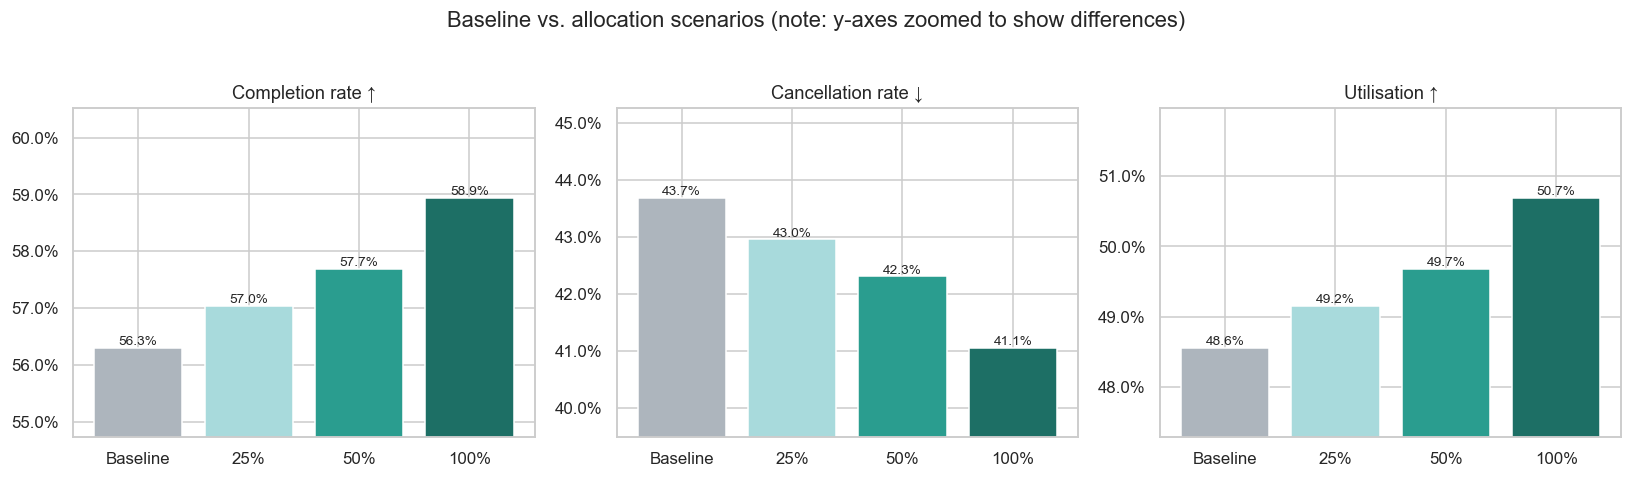

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
pal = ["#adb5bd", "#a8dadc", "#2a9d8f", "#1d6f65"]
for ax, col, t in zip(axes, ["Completion rate", "Cancellation rate", "Utilisation"],
                      ["Completion rate ↑", "Cancellation rate ↓", "Utilisation ↑"]):
    vals = sim[col]
    bars = ax.bar(range(len(vals)), vals, color=pal)
    ax.set_xticks(range(len(vals)), ["Baseline", "25%", "50%", "100%"])
    lo, hi_ = vals.min(), vals.max(); pad = max((hi_ - lo) * 0.6, 0.01)
    ax.set_ylim(lo - pad, hi_ + pad); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=1))
    ax.bar_label(bars, labels=[f"{v:.1%}" for v in vals], fontsize=9)
    ax.set_title(t)
plt.suptitle("Baseline vs. allocation scenarios (note: y-axes zoomed to show differences)", y=1.03)
plt.tight_layout(); plt.show()

In [21]:
s50 = impact.loc["50% reallocation"]
print("KEY NUMBERS FOR THE DECK")
print(f"• Baseline: completion {BASE_COMPLETION:.1%}, cancellation {BASE_CANCEL:.1%}, utilisation {BASE_UTIL:.1%}")
print(f"• Peak hours ({peak_txt}) carry {orders.is_peak.mean():.0%} of requests")
print(f"• Top-tier completion {prof.loc['Top 25%','completion_rate']:.0%} vs. Bottom-tier {prof.loc['Bottom 25%','completion_rate']:.0%}")
print(f"• Bottom tier handles {prof.loc['Bottom 25%','share_of_peak_orders']:.0%} of peak orders")
print(f"• 50% scenario: +{s50['Completion increase (pp)']:.1f} pp completion, -{s50['Cancellation decrease (pp)']:.1f} pp cancellation, "
      f"+{s50['Utilisation increase (pp)']:.1f} pp utilisation, ≈{s50['Extra completed deliveries']:,.0f} extra deliveries "
      f"(≈{s50['Extra trip value (Ksh / month)']:,.0f} Ksh/month)")

KEY NUMBERS FOR THE DECK
• Baseline: completion 56.3%, cancellation 43.7%, utilisation 48.6%
• Peak hours (12:00, 13:00, 14:00, 15:00, 16:00, 17:00) carry 59% of requests
• Top-tier completion 68% vs. Bottom-tier 40%
• Bottom tier handles 19% of peak orders
• 50% scenario: +1.4 pp completion, -1.4 pp cancellation, +1.1 pp utilisation, ≈1,446 extra deliveries (≈13,013 Ksh/month)


## Assumptions and limitations
- **Association, not causation.** We assume a reassigned order would perform like the higher tiers' orders in the same hour and vehicle class. Part of the gap may reflect *where* couriers work, not *how* they work.
- **Capacity is estimated.** Daily idle time is spread across hours in proportion to activity. Couriers might not actually take extra orders at those times, so the capped scenarios are deliberately conservative.
- **eWAKA influences dispatch but doesn't control it.** Bolt's algorithm assigns orders. eWAKA's levers are scheduling, shifts, vehicle allocation, coaching, incentives, and working with Bolt.
- **The data gets thin after the bicycles were dropped (Mar 2026).** Results mostly reflect the 2025 bicycle-heavy fleet. The tier logic still applies to motorbikes but should be re-checked on newer data.
- **Customer cancellations are only partly within eWAKA's control.** The simulation reduces them only through the higher tiers' faster, more reliable service.
- **Revenue is gross trip value**, not eWAKA's net revenue.

## Recommended next steps
1. Recompute tiers every week and pilot the peak-hour allocation with one group of couriers for 4 weeks, compared against a control group.
2. Add real-time alerts for unanswered orders, which are the largest courier-side loss.
3. Ask eWAKA for its daily performance thresholds and commission terms, so the tier cut-offs and Ksh impact use its real numbers.